# RAS 585: Machine Learning and Artificial Intelligence 
## Assignment 2
-------
### Part 1

In [326]:
from skimage import data
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering

Impory coffee image

width: 600, height: 400


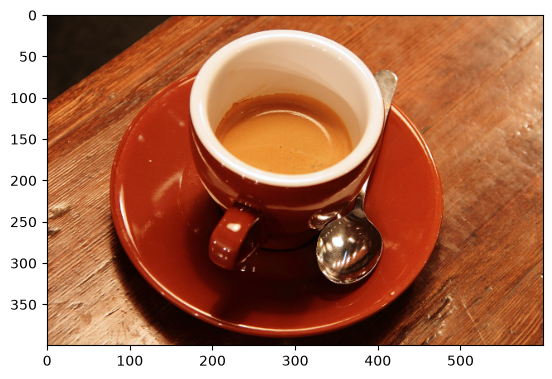

In [327]:
img = data.coffee()
plt.imshow(img)

height, width = img.shape[:2]
print(f"width: {width}, height: {height}")

Define functions for each part

In [328]:
def pad_image(img, window_size):
    h, w = img.shape[:2]

    h_pad = (window_size - h % window_size) % window_size
    w_pad = (window_size - w % window_size) % window_size

    return np.pad(
        img,
        ((0, h_pad), (0, w_pad), (0, 0)),
        mode="reflect"
    )

def get_windows(img, window_size):
    img = pad_image(img, window_size)
    h, w = img.shape[:2]
    windows = []

    for y in range(0, h, window_size):
        for x in range(0, w, window_size):
            window = img[y:y+window_size, x:x+window_size]
            windows.append(window.flatten('F'))

    return np.array(windows), h, w 

def reconstruct_image(windows, labels, height, width, window_size): 
    reconstructed = np.zeros((height, width, 3))

    representatives = {}
    i = 0

    for cluster_id in np.unique(labels):
        cluster_windows = windows[labels == cluster_id]
        representatives[cluster_id] = cluster_windows.mean(axis=0)

    for y in range(0, height, window_size):
        for x in range(0, width, window_size):

            # Get representative for this window's cluster
            flat_window = representatives[labels[i]]

            # Undo flatten("F")
            window = flat_window.reshape(
                (window_size, window_size, 3),
                order="F"
            )

            reconstructed[y:y+window_size, x:x+window_size] = window

            i += 1

    return reconstructed.astype(np.uint8)

def agglomerative_hierarchical_compression(windows, clusters): 
    clustering = AgglomerativeClustering(
        n_clusters=clusters,
        linkage="single",
        metric="euclidean"
    )
    labels = clustering.fit_predict(windows)
    return labels

def kmeans_compression(windows, clusters):
    kmeans = KMeans(n_clusters=clusters, init='k-means++', random_state=42)
    kmeans.fit(windows)
    labels = kmeans.labels_
    return labels

def compression(img, window_size, clusters, output_dir, type):
    original_h, original_w = img.shape[:2]
    windows, h, w = get_windows(img.copy(), window_size)

    match type:
        case "hierarchical":
            labels = agglomerative_hierarchical_compression(windows, clusters)

        case "kmeans":
            labels = kmeans_compression(windows, clusters)

        case _:
            raise ValueError(f"Unknown compression method: {type}")

    reconstructed = reconstruct_image(windows, labels, h, w, window_size)[:original_h, :original_w]

    export_jpg(reconstructed, output_dir)
    compress_rate = get_compression_rate(original_h, original_w, window_size, labels)
    recon_error = get_reconstruction_error(img, reconstructed)
    mse = get_mean_reconstruction_error(img, reconstructed)

    return reconstructed, compress_rate, recon_error, mse

def get_compression_rate(h, w, window_size, labels):
    original = h * w * 3 * 8
    k = len(np.unique(labels))

    num_windows = len(labels)
    bits_per_label = math.ceil(math.log2(k))
    label_bits = num_windows * bits_per_label
    representative_bits = window_size**2 * k * 3 * 8
    compressed = representative_bits + label_bits

    return compressed / original

def get_reconstruction_error(original, reconstructed): 
    original = original.astype(np.float64)
    reconstructed = reconstructed.astype(np.float64)

    return np.sum((original - reconstructed) ** 2)

def get_mean_reconstruction_error(original, reconstructed): 
    original = original.astype(np.float64)
    reconstructed = reconstructed.astype(np.float64)

    return np.mean((original - reconstructed) ** 2)

def export_jpg(img_arr, ouput_dir):
    img = Image.fromarray(img_arr)
    img.save(f"{ouput_dir}.jpg")


### 1. Image compression with hierarchical clustering
### 3. Image compression with k-means clustering

FileNotFoundError: [Errno 2] No such file or directory: '../results/heirarchical/compressed_k6_c20.jpg'

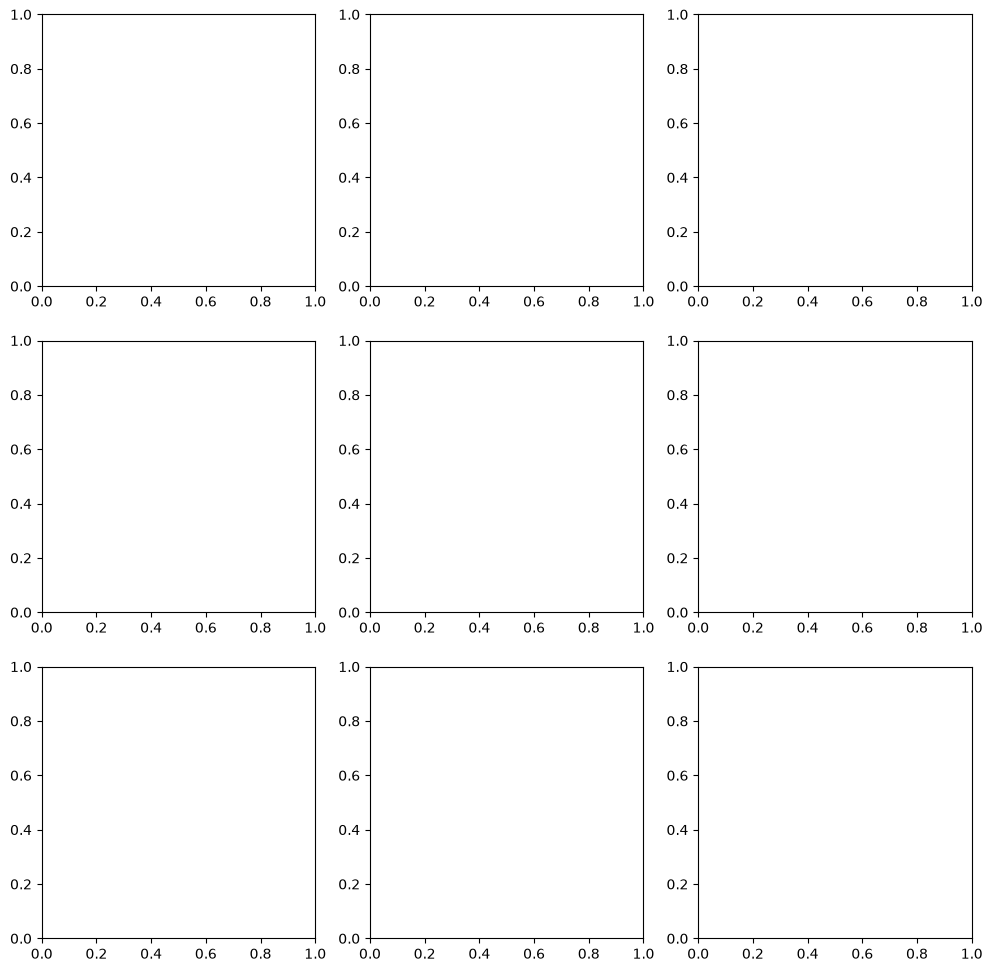

In [ ]:
clusters = [6, 10, 14]
window_sizes = [20, 50, 80]

compression_types = [
    "hierarchical",
    "kmeans"
]

results = []

for compression_type in compression_types:

    fig, axes = plt.subplots(3, 3, figsize=(12, 12))

    for i, k in enumerate(clusters):
        for j, c in enumerate(window_sizes):

            output_dir = (
                f"../results/{compression_type}/"
                f"compressed_k{k}_c{c}"
            )

            reconstructed, compress_rate, recon_error, mse = compression(
                img,
                window_size=c,
                clusters=k,
                output_dir=output_dir,
                type=compression_type
            )

            # Store results
            results.append({
                "method": compression_type,
                "image_path": f"{output_dir}.jpg",
                "k": k,
                "c": c,
                "compression_rate": compress_rate,
                "reconstruction_error": recon_error,
                "mean_reconstruction_error": mse,
            })

            # Add reconstructed image to 3x3 figure
            axes[i, j].imshow(reconstructed)
            axes[i, j].set_title(f"k = {k}, c = {c}")
            axes[i, j].axis("off")

    fig.suptitle(
        f"{compression_type.capitalize()} Compression",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


# Save everything to one CSV
results_df = pd.DataFrame(results)

results_df.to_csv(
    "../results/results.csv",
    index=False
)

results_df

### Part 2

In [340]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt
import math

In [331]:
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data    # NumPy array of shape (150, 4)
y = iris.target  # Species labels (0, 1, 2)

print("Features:", iris.feature_names)
print("Targets:", iris.target_names)

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Targets: ['setosa' 'versicolor' 'virginica']


In [ ]:
def get_setosa_only():
    setosa_index = list(iris.target_names).index('setosa')
    return X[y == setosa_index]

def gauss_kernel(u):
    d = len(u)
    return (1 / (2 * np.pi) ** (d / 2)) * np.exp(-np.sum(u ** 2) / 2)

def kernel_estimator(x, samples, h):
    N, d = samples.shape

    total = 0

    for sample in samples:
        u = (x - sample) / h
        total += gauss_kernel(u)

    return total / (N * h ** d)

def plot_kernel_estimator(samples, h, names):
    means = np.mean(samples, axis=0)
    num_features = len(means)

    # Maximum of 4 plots per row
    cols = min(4, num_features)
    rows = math.ceil(num_features / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(4 * cols, 4 * rows),
        squeeze=False
    )

    # Flatten so we can index axes[i]
    axes = axes.flatten()

    for i in range(num_features):
        x_vals = np.linspace(
            samples[:, i].min(),
            samples[:, i].max(),
            100
        )

        density = []

        for value in x_vals:
            x = means.copy()
            x[i] = value

            density.append(
                kernel_estimator(x, samples, h)
            )

        axes[i].plot(x_vals, density)
        axes[i].set_title(names[i])
        axes[i].set_xlabel(names[i])
        axes[i].set_ylabel("Density")

    # Remove unused plots
    for i in range(num_features, len(axes)):
        fig.delaxes(axes[i])

    fig.suptitle(f"Kernel Density Estimate (h = {h})")
    plt.tight_layout()
    plt.show()

def k_nearest_classification(X, y, k):
    knn_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

    knn_pipeline.fit(X, y)
    return knn_pipeline

def tree_classifier(X_train, y_train):
    clf = DecisionTreeClassifier(criterion='gini')
    clf.fit(X_train, y_train)
    return clf

def lda_classifier(X_train, y_train):
    lda = LinearDiscriminantAnalysis()
    lda.fit(X_train, y_train)
    return lda

def display_conf_matrix(classifier, X_test, y_test, names, ax):
    y_preds = classifier.predict(X_test)
    cm = confusion_matrix(y_test, y_preds)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=names
    )

    disp.plot(cmap=plt.cm.Blues, ax=ax)
    

In [334]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.5,          # 50% of data goes to the test set
    random_state=42,        
    stratify=y              # Enforces stratified splitting based on y labels
)

k = 3: Accuracy = 0.9200
k = 7: Accuracy = 0.9333
k = 11: Accuracy = 0.9467
k = 15: Accuracy = 0.9200


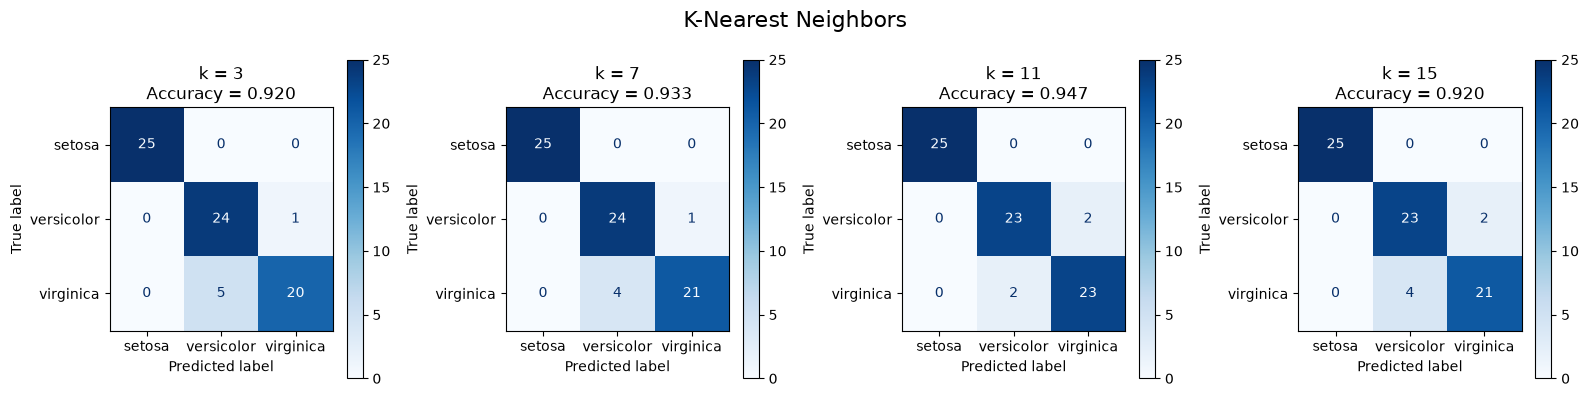

In [335]:
ks = [3, 7, 11, 15]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, k in enumerate(ks):
    clf = k_nearest_classification(X_train, y_train, k)

    y_preds = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_preds)

    print(f"k = {k}: Accuracy = {accuracy:.4f}")

    display_conf_matrix(
        clf,
        X_test,
        y_test,
        iris.target_names,
        axes[i]
    )

    axes[i].set_title(f"k = {k}\nAccuracy = {accuracy:.3f}")

fig.suptitle("K-Nearest Neighbors", fontsize=16)
plt.tight_layout()
plt.show()



Decision Tree: Accuracy = 0.8800


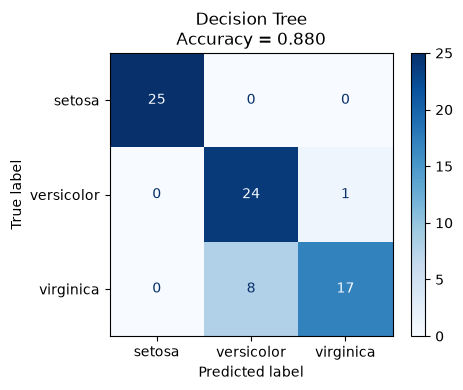

In [336]:
tree_clf = tree_classifier(X_train, y_train)

y_preds = tree_clf.predict(X_test)
accuracy = accuracy_score(y_test, y_preds)

print(f"\nDecision Tree: Accuracy = {accuracy:.4f}")

fig, ax = plt.subplots(figsize=(5, 4))

display_conf_matrix(
    tree_clf,
    X_test,
    y_test,
    iris.target_names,
    ax
)

ax.set_title(f"Decision Tree\nAccuracy = {accuracy:.3f}")

plt.tight_layout()
plt.show()


LDA: Accuracy = 0.9867


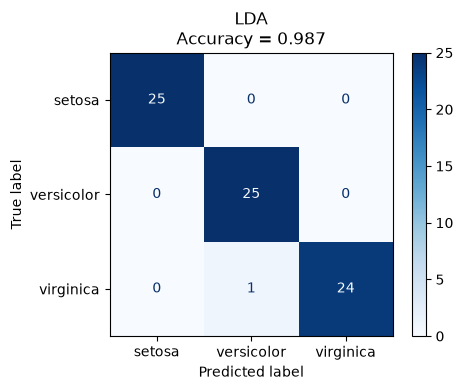

In [337]:
lda_clf = lda_classifier(X_train, y_train)

y_preds = lda_clf.predict(X_test)
accuracy = accuracy_score(y_test, y_preds)

print(f"\nLDA: Accuracy = {accuracy:.4f}")

fig, ax = plt.subplots(figsize=(5, 4))

display_conf_matrix(
    lda_clf,
    X_test,
    y_test,
    iris.target_names,
    ax
)

ax.set_title(f"LDA\nAccuracy = {accuracy:.3f}")

plt.tight_layout()
plt.show()

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")  # load a pretrained YOLO26n detection model

In [339]:
results = model("./Assignment 2_image.jpg", save=True)  # predict and save the annotated image


image 1/1 /home/hunter/Desktop/github/ML_coffee_and_iris/scr/Assignment 2_image.jpg: 352x640 2 cats, 18.6ms
Speed: 3.3ms preprocess, 18.6ms inference, 1.6ms postprocess per image at shape (1, 3, 352, 640)
Results saved to /home/hunter/Desktop/github/ML_coffee_and_iris/runs/detect/predict
